# Vpliv hitrosti in vrste meta na odbijanje v MLB (sezona 2025)

Podatki so pridobljeni s strani Baseball Savant (Statcast). Uporabljam dve tabeli:
- **hitrosti**: povprečna hitrost, vrtenje in gibanje vsake vrste meta za vsakega metalca,
- **rezultati**: kaj so odbijalci dosegli proti tej vrsti meta (povprečje, whiff %, hitrost odboja ...).

In [1]:
import pandas as pd

hitrosti = pd.read_csv("podatki/savant_hitrosti/savant_hitrosti_2025.csv")
rezultati = pd.read_csv("podatki/savant_rezultati/savant_rezultati_2025.csv")

print("hitrosti:", hitrosti.shape)
print("rezultati:", rezultati.shape)

hitrosti: (3412, 10)
rezultati: (558, 13)


In [2]:
hitrosti.head()

,id_metalca,ime,ekipa,roka,vrsta_meta,delez,hitrost,vrtenje,gibanje_x,gibanje_z
0,657277,Logan Webb,Giants,R,FF,7.9,92.8,2118.0,-8.9,10.7
1,657277,Logan Webb,Giants,R,SI,33.6,92.6,1961.0,-15.7,0.5
2,657277,Logan Webb,Giants,R,FC,7.8,91.0,2227.0,-2.0,7.7
3,657277,Logan Webb,Giants,R,CH,24.1,86.5,1502.0,-8.5,-5.6
4,657277,Logan Webb,Giants,R,ST,26.6,84.6,2544.0,14.6,-0.5


In [3]:
podatki = pd.merge(hitrosti, rezultati, on=["id_metalca", "vrsta_meta"], how="inner")

print("združeno:", podatki.shape)
podatki.head()
#zdruzimo obe tabeli, obdrzimo le pare, ki so v obeh (how inner)

združeno: (558, 21)


,id_metalca,ime,ekipa,roka,vrsta_meta,delez,hitrost,vrtenje,gibanje_x,gibanje_z,...,meti,ba,woba,k_odstotek,whiff,hitrost_odboja,kot_odboja,hard_hit,sweet_spot,barrel
0,657277,Logan Webb,Giants,R,SI,33.6,92.6,1961.0,-15.7,0.5,...,1104,0.294,0.348,15.8,13.0,91.6,2.3,45.9,28.8,7.4
1,657277,Logan Webb,Giants,R,CH,24.1,86.5,1502.0,-8.5,-5.6,...,792,0.207,0.253,34.0,31.8,90.7,-2.6,44.5,30.8,8.2
2,657277,Logan Webb,Giants,R,ST,26.6,84.6,2544.0,14.6,-0.5,...,873,0.286,0.337,25.8,29.0,87.6,13.7,32.1,41.0,11.2
3,607074,Carlos Rodón,Yankees,L,FF,41.8,94.1,2347.0,10.8,17.6,...,1343,0.224,0.342,18.7,21.5,90.7,23.3,42.5,33.5,9.5
4,607074,Carlos Rodón,Yankees,L,SL,28.4,85.9,2633.0,-5.5,-0.8,...,912,0.133,0.219,39.2,40.3,88.1,9.8,35.7,34.1,6.2


In [4]:
podatki.isna().sum()

id_metalca        0
ime               0
ekipa             0
roka              0
vrsta_meta        0
delez             0
hitrost           0
vrtenje           0
gibanje_x         0
gibanje_z         0
pa                0
meti              0
ba                0
woba              0
k_odstotek        0
whiff             0
hitrost_odboja    0
kot_odboja        0
hard_hit          0
sweet_spot        0
barrel            0
dtype: int64

In [5]:
podatki["vrsta_meta"].value_counts()

vrsta_meta
FF    208
SI    100
SL     76
CH     54
ST     35
CU     34
FC     32
FS     17
SV      2
Name: count, dtype: int64

Po združevanju imamo 558 parov (metalec, vrsta meta) in nobene manjkajoče vrednosti.
Slurve (SV) ima samo dve vrstici, zato ga v nadaljnji analizi izpustimo.

In [6]:
podatki = podatki[podatki["vrsta_meta"] != "SV"]
print("brez SV:", podatki.shape)

brez SV: (556, 21)


## Opisne statistike

Najprej pogledamo osnovne statistike za štiri najpomembnejše stolpce:
- `hitrost`: povprečna hitrost meta (mph),
- `whiff`: odstotek zamahov, pri katerih odbijalec žoge ni zadel,
- `hitrost_odboja`: povprečna hitrost žoge po udarcu (mph),
- `ba`: povprečje udarcev (batting average).

In [7]:
stolpci = ["hitrost", "whiff", "hitrost_odboja", "ba"]
podatki[stolpci].describe().round(2)

,hitrost,whiff,hitrost_odboja,ba
count,556.00,556.00,556.00,556.00
mean,90.39,24.62,89.60,0.24
std,5.55,9.94,3.14,0.05
min,71.30,4.30,78.70,0.11
25%,86.28,16.98,87.50,0.20
50%,92.00,23.55,90.10,0.24
75%,94.72,31.22,91.90,0.28
max,101.20,56.60,95.90,0.42


In [8]:
povprecja = podatki.groupby("vrsta_meta")[stolpci].mean()
povprecja = povprecja.sort_values("hitrost", ascending=False)
povprecja = povprecja.round(2)
povprecja

,hitrost,whiff,hitrost_odboja,ba
vrsta_meta,,,,
FF,94.59,21.41,91.92,0.25
SI,93.92,13.36,90.22,0.28
FC,90.31,22.28,88.89,0.26
FS,86.54,33.91,87.33,0.21
SL,86.31,34.41,87.82,0.21
CH,85.40,31.81,86.46,0.21
ST,83.27,31.01,86.60,0.21
CU,80.63,35.03,87.41,0.20


## Povprečna hitrost po vrstah metov

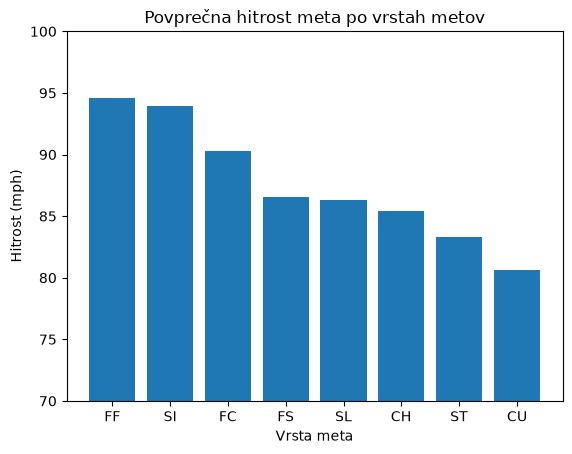

In [9]:
import matplotlib.pyplot as plt

plt.bar(povprecja.index, povprecja["hitrost"])
plt.title("Povprečna hitrost meta po vrstah metov")
plt.xlabel("Vrsta meta")
plt.ylabel("Hitrost (mph)")
plt.ylim(70, 100)
plt.show()

## Whiff % po vrstah metov

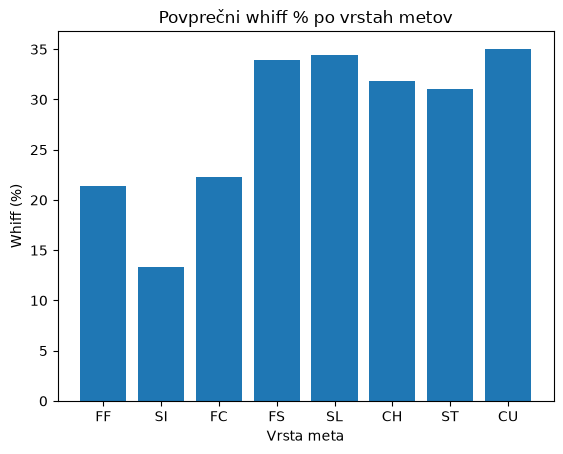

In [10]:
plt.bar(povprecja.index, povprecja["whiff"])
plt.title("Povprečni whiff % po vrstah metov")
plt.xlabel("Vrsta meta")
plt.ylabel("Whiff (%)")
plt.show()

Hitri meti (FF – four-seam fastball, SI – sinker) imajo najnižji whiff %, odbijalci jih torej najpogosteje zadenejo.
Počasnejši meti z več gibanja (SL – slider, CU – curveball, FS – splitter, CH – changeup, ST – sweeper)
imajo približno dvakrat več zgrešenih zamahov.
Sama hitrost torej ne pomeni, da je met težje zadeti; pomembna je tudi vrsta meta.

## Hitrost meta in hitrost odboja

Vsaka pika na grafu je en metalec z eno vrsto meta.

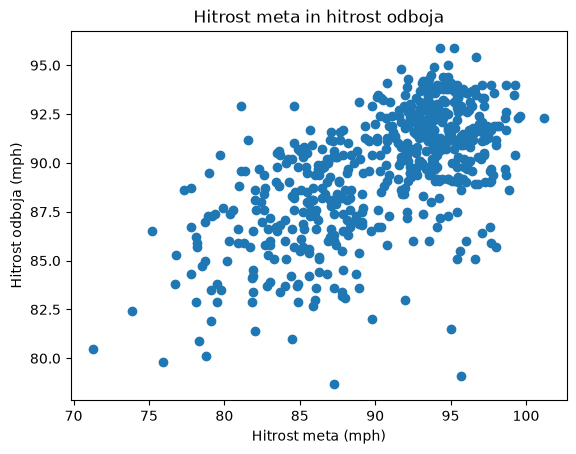

In [11]:
plt.scatter(podatki["hitrost"], podatki["hitrost_odboja"])
plt.title("Hitrost meta in hitrost odboja")
plt.xlabel("Hitrost meta (mph)")
plt.ylabel("Hitrost odboja (mph)")
plt.show()

In [ ]:
korelacija = podatki["hitrost"].corr(podatki["hitrost_odboja"])
print("korelacija:", round(korelacija, 2))
#corr racuna korelacijo med -1 in 1--> -1 eno pada drugo raste, blizu 1 eno pada drugo pada, 0 ni korelacije

korelacija: 0.61


## Hitrost meta in whiff %

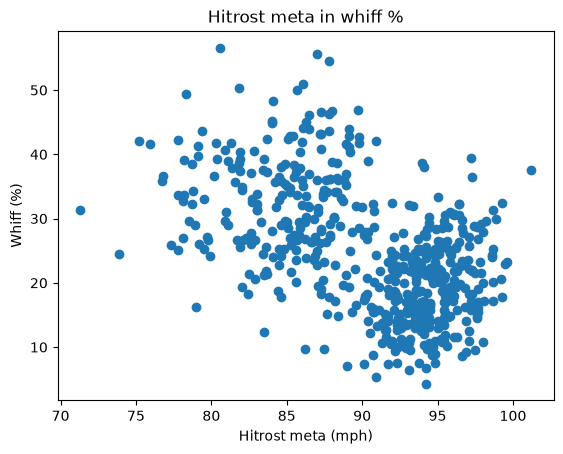

korelacija: -0.53


In [13]:
plt.scatter(podatki["hitrost"], podatki["whiff"])
plt.title("Hitrost meta in whiff %")
plt.xlabel("Hitrost meta (mph)")
plt.ylabel("Whiff (%)")
plt.show()

korelacija = podatki["hitrost"].corr(podatki["whiff"])
print("korelacija:", round(korelacija, 2))

## Samo four-seam fastball (FF)

Na prejšnjih grafih so pomešane vse vrste metov. Hitri meti so večinoma fastballi, počasni pa
slider, curveball in podobni, zato graf morda kaže razliko med vrstami metov, ne vpliv same hitrosti.
Zato pogledamo še samo eno vrsto meta: four-seam fastball, ki ima največ podatkov (208).

število FF: 208


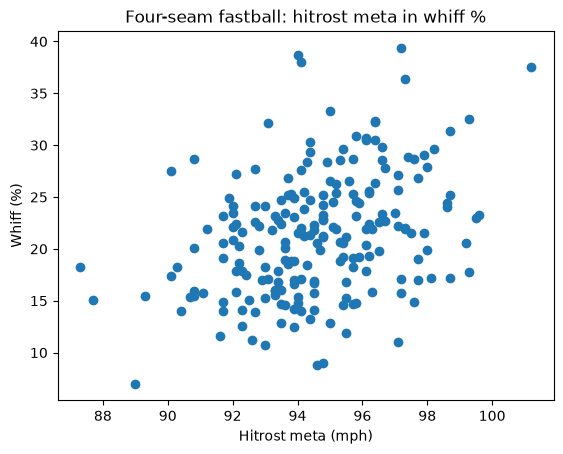

korelacija: 0.36


In [14]:
ff = podatki[podatki["vrsta_meta"] == "FF"]
print("število FF:", len(ff))

plt.scatter(ff["hitrost"], ff["whiff"])
plt.title("Four-seam fastball: hitrost meta in whiff %")
plt.xlabel("Hitrost meta (mph)")
plt.ylabel("Whiff (%)")
plt.show()

korelacija = ff["hitrost"].corr(ff["whiff"])
print("korelacija:", round(korelacija, 2))

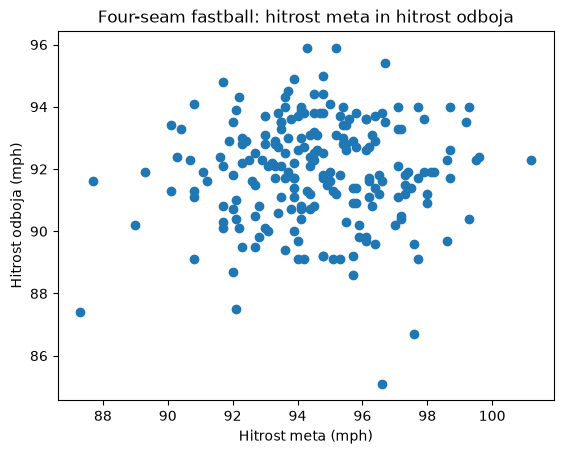

korelacija: 0.05


In [15]:
plt.scatter(ff["hitrost"], ff["hitrost_odboja"])
plt.title("Four-seam fastball: hitrost meta in hitrost odboja")
plt.xlabel("Hitrost meta (mph)")
plt.ylabel("Hitrost odboja (mph)")
plt.show()

korelacija = ff["hitrost"].corr(ff["hitrost_odboja"])
print("korelacija:", round(korelacija, 2))

Ko pogledamo vse vrste metov skupaj, se zdi, da hitrejši meti dobijo manj zgrešenih zamahov
(korelacija −0,53) in močnejše udarce (0,61). To je predvsem posledica razlike med vrstami metov:
fastballi so hitri, a jih je lažje zadeti, počasni meti z več gibanja pa so težji za zadeti.

Pri samih four-seam fastballih je slika drugačna: hitrejši fastball dobi več zgrešenih zamahov
(korelacija 0,36), na hitrost odboja pa hitrost skoraj ne vpliva (0,05).
Znotraj iste vrste meta je torej hitrost prednost za metalca, med različnimi vrstami pa je pomembnejša vrsta meta.